# Reconnaissance de Chiens et Chats (Version Locale)

Ce notebook gère l'extraction automatique du dataset `dogs-vs-cats.zip` et l'entraînement d'un modèle **MobileNetV2** sur votre machine locale.

**Étapes :**
1. Vérification de l'environnement (Stable TF + Metal)
2. Configuration et Extraction du Dataset
3. Organisation automatique des dossiers
4. Chargement et Augmentation des données
5. Construction et Entraînement du modèle
6. Prédiction

In [1]:
import os
import sys
import tensorflow as tf

print(f"Python : {sys.version}")
print(f"TensorFlow : {tf.__version__}")

# GPU Metal Check
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"✅ GPU Détecté : {gpu_devices[0]}")
else:
    print("⚠️ Aucun GPU détecté. L'entraînement sera lent sur CPU.")

# OpenMP conflict resolution
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

Python : 3.11.15 | packaged by conda-forge | (main, Mar  5 2026, 16:59:26) [Clang 19.1.7 ]
TensorFlow : 2.16.2
✅ GPU Détecté : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


## 1. Importation et Extraction
On utilise le fichier `dogs-vs-cats.zip` présent dans le dossier actuel.

In [2]:
import os
import shutil
import zipfile

# Chemin vers votre fichier zip local
ZIP_PATH = './dogs-vs-cats.zip'
WORKING_DIR = './'

if os.path.exists(ZIP_PATH):
    print("📦 Extraction de dogs-vs-cats.zip...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        # On extrait tout dans le dossier de travail
        zip_ref.extractall(WORKING_DIR)

    print("📦 Extraction de train.zip...")
    if os.path.exists(os.path.join(WORKING_DIR, 'train.zip')):
        with zipfile.ZipFile(os.path.join(WORKING_DIR, 'train.zip'), 'r') as zip_ref:
            zip_ref.extractall(WORKING_DIR)
    
    print("✅ Extraction terminée.")
else:
    print(f"❌ Erreur : Le fichier {ZIP_PATH} est introuvable.")

📦 Extraction de dogs-vs-cats.zip...
📦 Extraction de train.zip...
✅ Extraction terminée.


## 2. Organisation automatique des dossiers
Keras nécessite que les images soient dans des sous-dossiers par classe (`cats/` et `dogs/`).

In [3]:
base_dir = os.path.join(WORKING_DIR, 'train')
data_dir = os.path.join(WORKING_DIR, 'organized_data')
train_dir = os.path.join(data_dir, 'train')
train_cats_dir = os.path.join(train_dir, 'cats')
train_dogs_dir = os.path.join(train_dir, 'dogs')

# Création des dossiers
os.makedirs(train_cats_dir, exist_ok=True)
os.makedirs(train_dogs_dir, exist_ok=True)

if os.path.exists(base_dir):
    fnames = os.listdir(base_dir)
    print(f"Tri de {len(fnames)} images...")

    for fname in fnames:
        if fname.startswith('cat'):
            # On utilise copy2 au lieu de move si on veut garder les originaux, 
            # ou move pour gagner de l'espace.
            shutil.move(os.path.join(base_dir, fname), os.path.join(train_cats_dir, fname))
        elif fname.startswith('dog'):
            shutil.move(os.path.join(base_dir, fname), os.path.join(train_dogs_dir, fname))

    print(f"✅ Organisation terminée.")
    print(f"Chats : {len(os.listdir(train_cats_dir))}")
    print(f"Chiens : {len(os.listdir(train_dogs_dir))}")
else:
    print("❌ Erreur : Le dossier 'train' extrait est introuvable.")

Tri de 25000 images...
✅ Organisation terminée.
Chats : 12500
Chiens : 12500


## 3. Chargement et Configuration

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

BATCH_SIZE = 32
IMG_SIZE = (160, 160)
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
  train_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=IMG_SIZE,
  batch_size=BATCH_SIZE)

val_ds = tf.keras.utils.image_dataset_from_directory(
  train_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=IMG_SIZE,
  batch_size=BATCH_SIZE)

class_names = train_ds.class_names
print(f"Classes : {class_names}")

Found 25000 files belonging to 2 classes.
Using 20000 files for training.


2026-04-10 21:29:32.946765: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-04-10 21:29:32.946787: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-04-10 21:29:32.946796: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.00 GB
2026-04-10 21:29:32.947092: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-10 21:29:32.947105: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 25000 files belonging to 2 classes.
Using 5000 files for validation.
Classes : ['cats', 'dogs']


## 4. Modèle et Entraînement

In [5]:
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal"),
  layers.RandomRotation(0.1),
])

base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False

inputs = tf.keras.Input(shape=(160, 160, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1)(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

epochs = 5 
history = model.fit(train_ds, epochs=epochs, validation_data=val_ds)

# On sauvegarde le modèle localement
model.save('./dog_cat_model_local.keras')

Epoch 1/5


2026-04-10 21:29:34.634722: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step - accuracy: 0.8238 - loss: 0.3405 - val_accuracy: 0.9492 - val_loss: 0.1341
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.9424 - loss: 0.1438 - val_accuracy: 0.9640 - val_loss: 0.0893
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.9567 - loss: 0.1111 - val_accuracy: 0.9712 - val_loss: 0.0725
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.9610 - loss: 0.0982 - val_accuracy: 0.9748 - val_loss: 0.0648
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 39ms/step - accuracy: 0.9627 - loss: 0.0922 - val_accuracy: 0.9774 - val_loss: 0.0595


## 5. Visualisation et Test

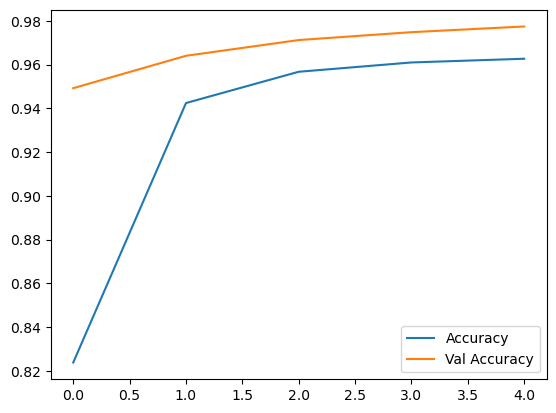

In [6]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(acc, label='Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.legend()
plt.show()

def predict_image(img_path):
    if not os.path.exists(img_path):
        print(f"❌ Fichier introuvable : {img_path}")
        return
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    score = tf.nn.sigmoid(model.predict(img_array)[0])
    print(f"{100 * (1 - score[0]):.2f}% Chat | {100 * score[0]:.2f}% Chien")

# Exemple d'utilisation :
# predict_image('./ma_photo.jpg')

## 6. Interface de Prédiction Interactive
Exécutez la cellule ci-dessous pour lancer l'interface de test.

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import io
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Chargement du modèle (si pas déjà fait)
try:
    if 'model' not in globals():
        model = tf.keras.models.load_model('./dog_cat_model_local.keras')
        print("✅ Modèle chargé avec succès.")
except Exception as e:
    print(f"❌ Erreur lors du chargement : {e}")

# 2. Widgets de l'interface
uploader = widgets.FileUpload(accept='image/*', multiple=False)
output = widgets.Output()
label_res = widgets.Label(value="Attente d'une image...")

def on_upload_change(change):
    with output:
        clear_output()
        if not uploader.value:
            return
        
        # Récupérer l'image uploadée
        uploaded_file = list(uploader.value.values())[0]
        content = uploaded_file['content']
        img = Image.open(io.BytesIO(content))
        
        # Pré-traitement pour le modèle
        img_resized = img.resize((160, 160))
        img_array = tf.keras.utils.img_to_array(img_resized)
        img_array = tf.expand_dims(img_array, 0)
        
        # Prédiction
        prediction = model.predict(img_array, verbose=0)
        score = tf.nn.sigmoid(prediction[0])
        
        # Analyse du résultat
        is_dog = score[0] > 0.5
        class_name = "CHIEN" if is_dog else "CHAT"
        confidence = score[0] if is_dog else 1 - score[0]
        
        # Affichage
        plt.figure(figsize=(6, 6))
        plt.imshow(img)
        plt.axis('off')
        color = 'green' if confidence > 0.8 else 'orange'
        plt.title(f"Résultat : {class_name} ({100*confidence:.1f}%)", color=color, fontsize=16, fontweight='bold')
        plt.show()
        
        label_res.value = f"Dernière analyse : C'est un {class_name} !"

uploader.observe(on_upload_change, names='value')

# Mise en page
ui = widgets.VBox([
    widgets.HTML("<h2>🖼️ Testeur de Chiens et Chats</h2>"),
    widgets.HTML("<p>Sélectionnez une image sur votre ordinateur pour l'analyser :</p>"),
    uploader,
    output,
    label_res
])

display(ui)

## 6. Interface de Prédiction Interactive
Exécutez la cellule ci-dessous pour lancer l'interface de test.

In [8]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import io
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Chargement du modèle (si pas déjà fait)
try:
    if 'model' not in globals():
        model = tf.keras.models.load_model('./dog_cat_model_local.keras')
        print("✅ Modèle chargé avec succès.")
except Exception as e:
    print(f"❌ Erreur lors du chargement : {e}")

# 2. Widgets de l'interface
uploader = widgets.FileUpload(accept='image/*', multiple=False)
output = widgets.Output()
label_res = widgets.Label(value="Attente d'une image...")

def on_upload_change(change):
    with output:
        clear_output()
        if not uploader.value:
            return
        
        # Récupérer l'image uploadée
        uploaded_file = list(uploader.value.values())[0]
        content = uploaded_file['content']
        img = Image.open(io.BytesIO(content))
        
        # Pré-traitement pour le modèle
        img_resized = img.resize((160, 160))
        img_array = tf.keras.utils.img_to_array(img_resized)
        img_array = tf.expand_dims(img_array, 0)
        
        # Prédiction
        prediction = model.predict(img_array, verbose=0)
        score = tf.nn.sigmoid(prediction[0])
        
        # Analyse du résultat
        is_dog = score[0] > 0.5
        class_name = "CHIEN" if is_dog else "CHAT"
        confidence = score[0] if is_dog else 1 - score[0]
        
        # Affichage
        plt.figure(figsize=(6, 6))
        plt.imshow(img)
        plt.axis('off')
        color = 'green' if confidence > 0.8 else 'orange'
        plt.title(f"Résultat : {class_name} ({100*confidence:.1f}%)", color=color, fontsize=16, fontweight='bold')
        plt.show()
        
        label_res.value = f"Dernière analyse : C'est un {class_name} !"

uploader.observe(on_upload_change, names='value')

# Mise en page
ui = widgets.VBox([
    widgets.HTML("<h2>🖼️ Testeur de Chiens et Chats</h2>"),
    widgets.HTML("<p>Sélectionnez une image sur votre ordinateur pour l'analyser :</p>"),
    uploader,
    output,
    label_res
])

display(ui)